In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

res_py = pd.read_csv('../resultados/resumen.csv')
res_c = pd.read_csv('../resultados/c_cuda_resumen.csv')

print('=== Python / PyCUDA ===')
print(res_py[['filtro', 'resolucion', 'mascara', 'hilos_bloque', 'cpu_estado', 'cpu_med_ms', 'gpu_kernel_ms', 'gpu_total_ms', 'aceleracion_computo']].to_string())
print('\n=== C / CUDA C ===')
print(res_c[['filtro', 'resolucion', 'mascara', 'hilos_bloque', 'cpu_med_ms', 'gpu_kernel_ms', 'gpu_total_ms', 'aceleracion_computo']].to_string())

=== Python / PyCUDA ===
        filtro resolucion mascara  hilos_bloque     cpu_estado   cpu_med_ms  gpu_kernel_ms  gpu_total_ms  aceleracion_computo
0        media  2050x2050     3x3           256     completada   10854.0950         0.1938        2.2204             56018.25
1        media  4000x4000     3x3           256     completada   42955.4799         0.7704        9.1092             55755.06
2      nitidez  4000x4000     3x3           256     completada   24355.1464         0.7176        6.3501             33941.24
3   laplaciano  4000x4000     3x3           256     completada   24349.5916         0.7169        6.4477             33963.79
4        media  2000x2000     9x9           256     completada   50546.2244         0.6734        2.2260             75060.33
5        media  4000x4000     9x9           256     completada  217254.8317         2.7157        8.5228             80000.16
6        media  6000x6000     9x9           256  no_completada          NaN         6.0857    

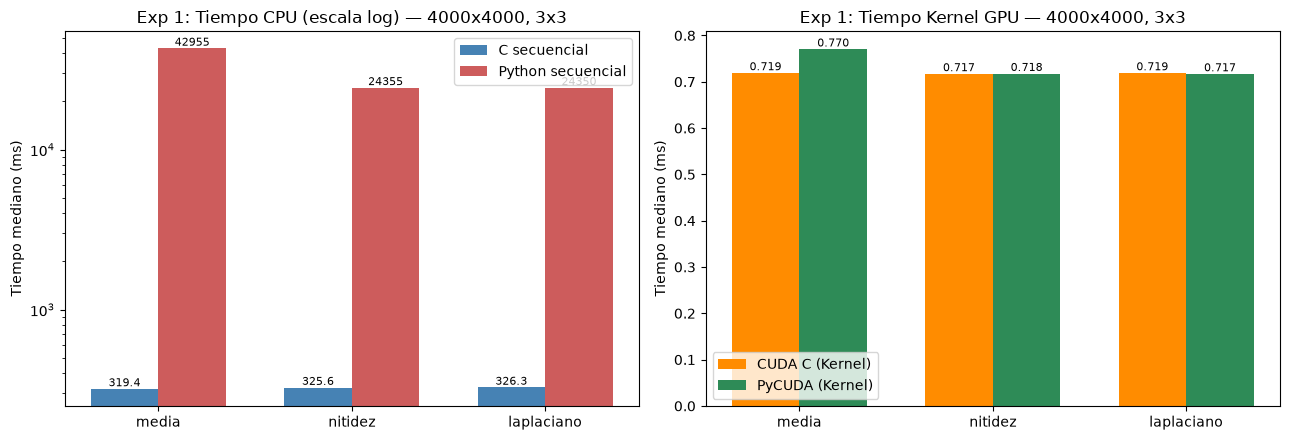

In [2]:
# Experimento 1: comparar filtros 3x3 sobre 4000x4000 (las 4 versiones)
filtros = ['media', 'nitidez', 'laplaciano']
e1_c = res_c[(res_c['resolucion'] == '4000x4000') & (res_c['mascara'] == '3x3') & (res_c['hilos_bloque'] == 256)].drop_duplicates('filtro', keep='first').set_index('filtro').loc[filtros]
e1_p = res_py[(res_py['resolucion'] == '4000x4000') & (res_py['mascara'] == '3x3') & (res_py['hilos_bloque'] == 256)].drop_duplicates('filtro', keep='first').set_index('filtro').loc[filtros]

x = np.arange(len(filtros))
w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

b1 = axes[0].bar(x - w/2, e1_c['cpu_med_ms'], width=w, color='steelblue', label='C secuencial')
b2 = axes[0].bar(x + w/2, e1_p['cpu_med_ms'], width=w, color='indianred', label='Python secuencial')
axes[0].set_yscale('log')
axes[0].set_xticks(x, filtros)
axes[0].set_title('Exp 1: Tiempo CPU (escala log) — 4000x4000, 3x3')
axes[0].set_ylabel('Tiempo mediano (ms)')
axes[0].legend()
axes[0].bar_label(b1, fmt='%.1f', fontsize=8)
axes[0].bar_label(b2, fmt='%.0f', fontsize=8)

b3 = axes[1].bar(x - w/2, e1_c['gpu_kernel_ms'], width=w, color='darkorange', label='CUDA C (Kernel)')
b4 = axes[1].bar(x + w/2, e1_p['gpu_kernel_ms'], width=w, color='seagreen', label='PyCUDA (Kernel)')
axes[1].set_xticks(x, filtros)
axes[1].set_title('Exp 1: Tiempo Kernel GPU — 4000x4000, 3x3')
axes[1].set_ylabel('Tiempo mediano (ms)')
axes[1].legend()
axes[1].bar_label(b3, fmt='%.3f', fontsize=8)
axes[1].bar_label(b4, fmt='%.3f', fontsize=8)

plt.tight_layout()
plt.savefig('../resultados/exp1_filtros.png', dpi=150)
plt.show()

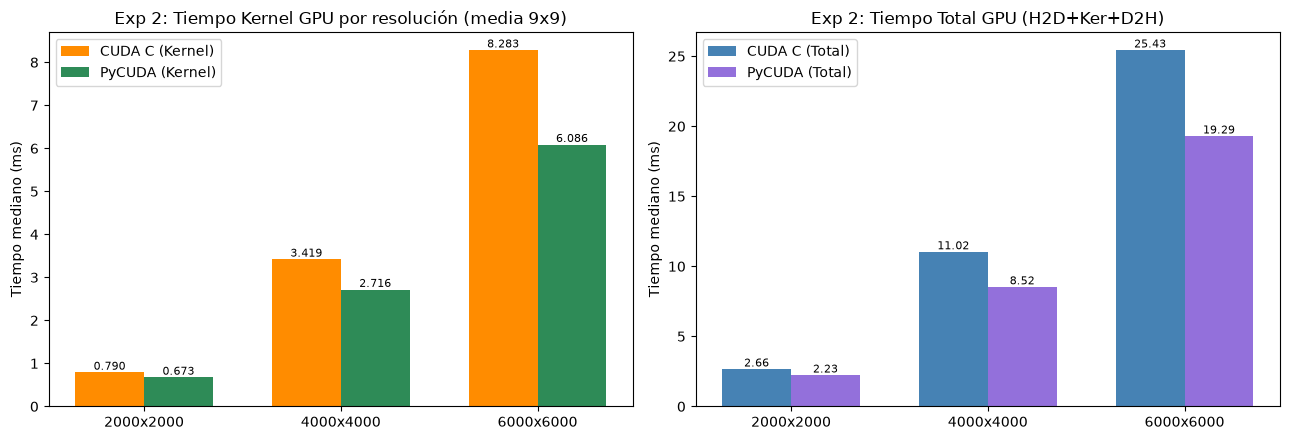

In [3]:
# Experimento 2: comparar resoluciones con media 9x9
resols = ['2000x2000', '4000x4000', '6000x6000']
e2_c = res_c[(res_c['filtro'] == 'media') & (res_c['mascara'] == '9x9') & (res_c['hilos_bloque'] == 256) & (res_c['resolucion'].isin(resols))].drop_duplicates('resolucion', keep='first').set_index('resolucion').loc[resols]
e2_p = res_py[(res_py['filtro'] == 'media') & (res_py['mascara'] == '9x9') & (res_py['hilos_bloque'] == 256) & (res_py['resolucion'].isin(resols))].drop_duplicates('resolucion', keep='first').set_index('resolucion').loc[resols]

x = np.arange(len(resols))
w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

b1 = axes[0].bar(x - w/2, e2_c['gpu_kernel_ms'], width=w, color='darkorange', label='CUDA C (Kernel)')
b2 = axes[0].bar(x + w/2, e2_p['gpu_kernel_ms'], width=w, color='seagreen', label='PyCUDA (Kernel)')
axes[0].set_xticks(x, resols)
axes[0].set_title('Exp 2: Tiempo Kernel GPU por resolución (media 9x9)')
axes[0].set_ylabel('Tiempo mediano (ms)')
axes[0].legend()
axes[0].bar_label(b1, fmt='%.3f', fontsize=8)
axes[0].bar_label(b2, fmt='%.3f', fontsize=8)

b3 = axes[1].bar(x - w/2, e2_c['gpu_total_ms'], width=w, color='steelblue', label='CUDA C (Total)')
b4 = axes[1].bar(x + w/2, e2_p['gpu_total_ms'], width=w, color='mediumpurple', label='PyCUDA (Total)')
axes[1].set_xticks(x, resols)
axes[1].set_title('Exp 2: Tiempo Total GPU (H2D+Ker+D2H)')
axes[1].set_ylabel('Tiempo mediano (ms)')
axes[1].legend()
axes[1].bar_label(b3, fmt='%.2f', fontsize=8)
axes[1].bar_label(b4, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig('../resultados/exp2_resolucion.png', dpi=150)
plt.show()

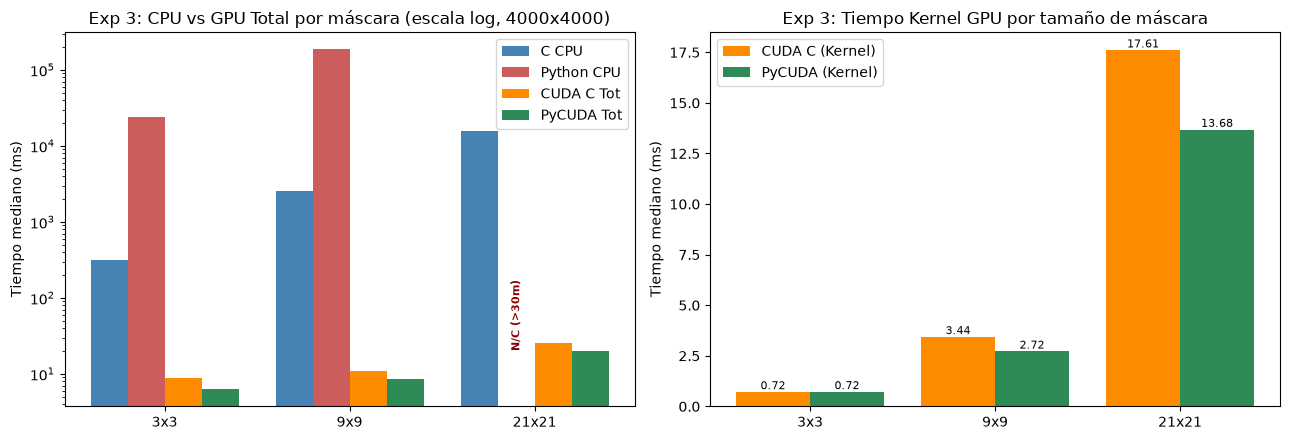

In [4]:
# Experimento 3: comparar tamanos de mascara sobre 4000x4000
mascs = ['3x3', '9x9', '21x21']
idx_c = res_c[res_c['mascara'] == '21x21'].index[0]
e3_c = res_c.iloc[idx_c - 2 : idx_c + 1].set_index('mascara').loc[mascs]
idx_p = res_py[res_py['mascara'] == '21x21'].index[0]
e3_p = res_py.iloc[idx_p - 2 : idx_p + 1].set_index('mascara').loc[mascs]

x = np.arange(len(mascs))
w = 0.2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

b1 = axes[0].bar(x - 1.5*w, e3_c['cpu_med_ms'], width=w, color='steelblue', label='C CPU')
b2 = axes[0].bar(x - 0.5*w, e3_p['cpu_med_ms'].fillna(0), width=w, color='indianred', label='Python CPU')
b3 = axes[0].bar(x + 0.5*w, e3_c['gpu_total_ms'], width=w, color='darkorange', label='CUDA C Tot')
b4 = axes[0].bar(x + 1.5*w, e3_p['gpu_total_ms'], width=w, color='seagreen', label='PyCUDA Tot')
axes[0].set_yscale('log')
axes[0].set_xticks(x, mascs)
axes[0].set_title('Exp 3: CPU vs GPU Total por máscara (escala log, 4000x4000)')
axes[0].set_ylabel('Tiempo mediano (ms)')
axes[0].legend()

# Marcar 21x21 no completada en Python CPU
axes[0].text(2 - 0.5*w, 20, 'N/C (>30m)', rotation=90, ha='center', va='bottom', fontsize=8, color='darkred', fontweight='bold')

b5 = axes[1].bar(x - w, e3_c['gpu_kernel_ms'], width=2*w, color='darkorange', label='CUDA C (Kernel)')
b6 = axes[1].bar(x + w, e3_p['gpu_kernel_ms'], width=2*w, color='seagreen', label='PyCUDA (Kernel)')
axes[1].set_xticks(x, mascs)
axes[1].set_title('Exp 3: Tiempo Kernel GPU por tamaño de máscara')
axes[1].set_ylabel('Tiempo mediano (ms)')
axes[1].legend()
axes[1].bar_label(b5, fmt='%.2f', fontsize=8)
axes[1].bar_label(b6, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig('../resultados/exp3_mascara.png', dpi=150)
plt.show()

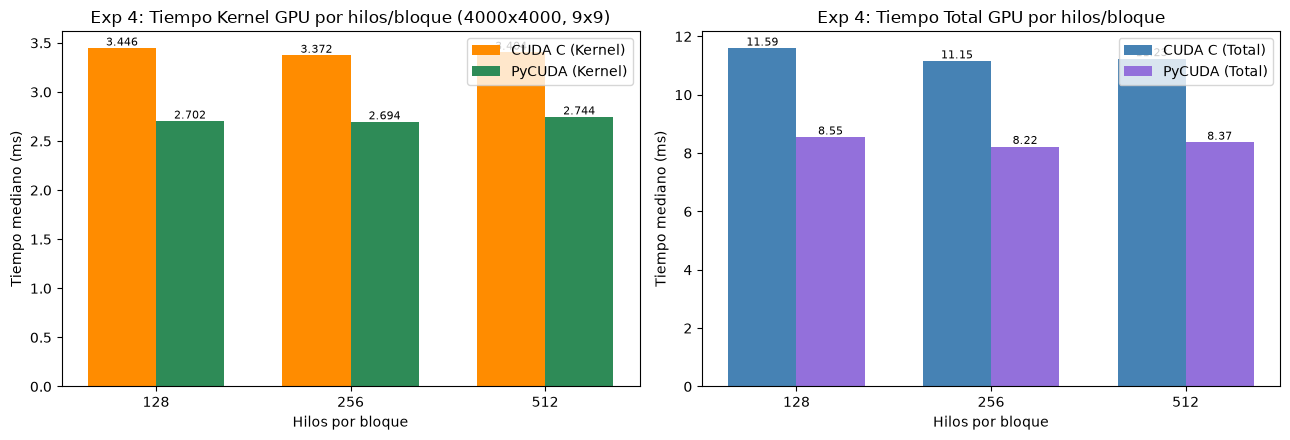

In [5]:
# Experimento 4: comparar hilos/bloque con media 9x9 sobre 4000x4000 (CUDA C vs PyCUDA)
hilos = [128, 256, 512]
e4_c = res_c[(res_c['filtro'] == 'media') & (res_c['mascara'] == '9x9') & (res_c['resolucion'] == '4000x4000') & (res_c['hilos_bloque'].isin(hilos))].drop_duplicates('hilos_bloque', keep='last').set_index('hilos_bloque').loc[hilos]
e4_p = res_py[(res_py['filtro'] == 'media') & (res_py['mascara'] == '9x9') & (res_py['resolucion'] == '4000x4000') & (res_py['hilos_bloque'].isin(hilos))].drop_duplicates('hilos_bloque', keep='last').set_index('hilos_bloque').loc[hilos]

x = np.arange(len(hilos))
w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

b1 = axes[0].bar(x - w/2, e4_c['gpu_kernel_ms'], width=w, color='darkorange', label='CUDA C (Kernel)')
b2 = axes[0].bar(x + w/2, e4_p['gpu_kernel_ms'], width=w, color='seagreen', label='PyCUDA (Kernel)')
axes[0].set_xticks(x, [str(h) for h in hilos])
axes[0].set_xlabel('Hilos por bloque')
axes[0].set_ylabel('Tiempo mediano (ms)')
axes[0].set_title('Exp 4: Tiempo Kernel GPU por hilos/bloque (4000x4000, 9x9)')
axes[0].legend()
axes[0].bar_label(b1, fmt='%.3f', fontsize=8)
axes[0].bar_label(b2, fmt='%.3f', fontsize=8)

b3 = axes[1].bar(x - w/2, e4_c['gpu_total_ms'], width=w, color='steelblue', label='CUDA C (Total)')
b4 = axes[1].bar(x + w/2, e4_p['gpu_total_ms'], width=w, color='mediumpurple', label='PyCUDA (Total)')
axes[1].set_xticks(x, [str(h) for h in hilos])
axes[1].set_xlabel('Hilos por bloque')
axes[1].set_ylabel('Tiempo mediano (ms)')
axes[1].set_title('Exp 4: Tiempo Total GPU por hilos/bloque')
axes[1].legend()
axes[1].bar_label(b3, fmt='%.2f', fontsize=8)
axes[1].bar_label(b4, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig('../resultados/exp4_hilos.png', dpi=150)
plt.show()